<a href="https://colab.research.google.com/github/AKookani/BrickwallCliffordCircuit/blob/main/Half_Chain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Half entropy

## Raw code

device: cuda
[1/11] p=0.00 done in 17s | elapsed 17s | remaining ~2m 47s (ETA 16:59:41)
[2/11] p=0.02 done in 25s | elapsed 42s | remaining ~3m 9s (ETA 17:00:28)
[3/11] p=0.04 done in 24s | elapsed 1m 6s | remaining ~2m 56s (ETA 17:00:39)
[4/11] p=0.06 done in 23s | elapsed 1m 29s | remaining ~2m 36s (ETA 17:00:43)
[5/11] p=0.08 done in 23s | elapsed 1m 52s | remaining ~2m 15s (ETA 17:00:44)
[6/11] p=0.10 done in 24s | elapsed 2m 16s | remaining ~1m 53s (ETA 17:00:47)
[7/11] p=0.12 done in 24s | elapsed 2m 40s | remaining ~1m 31s (ETA 17:00:49)
[8/11] p=0.14 done in 23s | elapsed 3m 3s | remaining ~1m 9s (ETA 17:00:49)
[9/11] p=0.16 done in 24s | elapsed 3m 27s | remaining ~46s (ETA 17:00:50)
[10/11] p=0.18 done in 24s | elapsed 3m 51s | remaining ~23s (ETA 17:00:51)
[11/11] p=0.20 done in 24s | elapsed 4m 15s | remaining ~0s (ETA 17:00:52)
Total wall time: 4m 15s


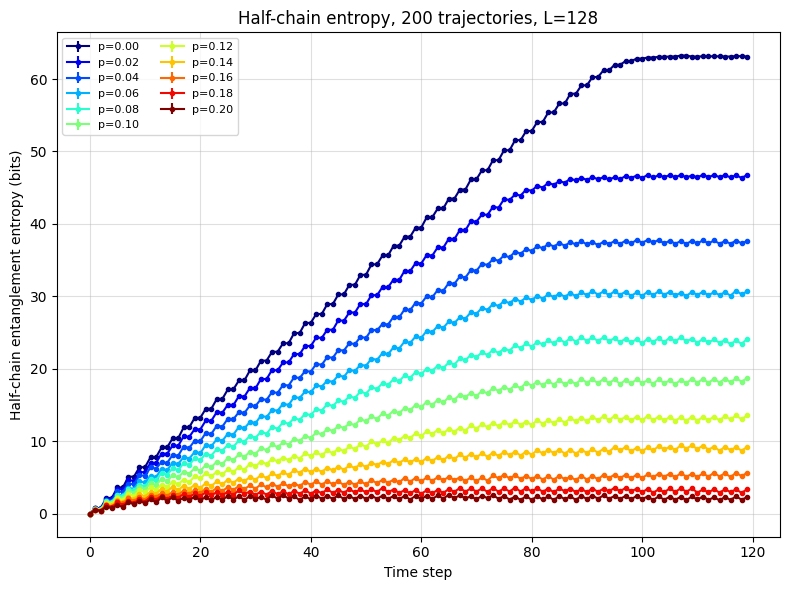

In [ ]:
import numpy as np
import torch
import os
import time
import datetime

# ---------------- Sp(4,2) precomputation (720 elements, one-time, cached) ----------------

def gf2_rank_full(matrix):
    m = (matrix.copy() % 2).astype(np.uint8)
    rows, cols = m.shape
    rank = 0
    for col in range(cols):
        pivot = None
        for r in range(rank, rows):
            if m[r, col]:
                pivot = r
                break
        if pivot is None:
            continue
        m[[rank, pivot]] = m[[pivot, rank]]
        for r in range(rows):
            if r != rank and m[r, col]:
                m[r] = (m[r] + m[rank]) % 2
        rank += 1
    return rank


def build_sp42(cache_path="sp42_table.npy"):
    if os.path.exists(cache_path):
        return np.load(cache_path)
    idx = np.arange(1 << 16, dtype=np.uint32)
    bits = ((idx[:, None] >> np.arange(16)) & 1).astype(np.uint8)
    mats = bits.reshape(-1, 4, 4)
    J = np.array([[0, 1, 0, 0],
                  [1, 0, 0, 0],
                  [0, 0, 0, 1],
                  [0, 0, 1, 0]], dtype=np.uint8)
    valid = []
    for M in mats:
        if gf2_rank_full(M) < 4:
            continue
        lhs = (M.T.astype(np.uint8) @ J @ M) % 2
        if np.array_equal(lhs, J):
            valid.append(M)
    table = np.stack(valid).astype(np.uint8)
    np.save(cache_path, table)
    return table


# ---------------- Tableau gate primitives (batched, in-place where possible) ----------------

def apply_hadamard(X, Z, q):
    xq = X[:, :, q].clone()
    zq = Z[:, :, q].clone()
    X[:, :, q] = zq
    Z[:, :, q] = xq


def apply_cnot(X, Z, c, t):
    X[:, :, t] ^= X[:, :, c]
    Z[:, :, c] ^= Z[:, :, t]


def apply_two_qubit_random(X, Z, a, b, sp42_table, batch, device, generator=None):
    n_elems = sp42_table.shape[0]
    idx = torch.randint(0, n_elems, (batch,), device=device, generator=generator)
    M = sp42_table[idx].float()  # (batch,4,4)
    vec = torch.stack([X[:, :, a], Z[:, :, a], X[:, :, b], Z[:, :, b]], dim=-1).float()  # (batch,n,4)
    new_vec = torch.einsum('bkl,bnl->bnk', M, vec)
    new_vec = torch.remainder(new_vec, 2).to(torch.uint8)
    X[:, :, a] = new_vec[..., 0]
    Z[:, :, a] = new_vec[..., 1]
    X[:, :, b] = new_vec[..., 2]
    Z[:, :, b] = new_vec[..., 3]


def brickwork_layer_batched(X, Z, t, system_qubits, sp42_table, batch, device, periodic=True, generator=None):
    L = len(system_qubits)
    offset = t % 2
    j = offset
    while j + 1 < L:
        apply_two_qubit_random(X, Z, system_qubits[j], system_qubits[j + 1], sp42_table, batch, device, generator)
        j += 2
    if periodic and offset == 1 and L % 2 == 0:
        apply_two_qubit_random(X, Z, system_qubits[L - 1], system_qubits[0], sp42_table, batch, device, generator)


def measure_layer_batched(X, Z, system_qubits, p_measure, batch, device, generator=None):
    do_measure = torch.rand((batch, len(system_qubits)), device=device, generator=generator) < p_measure
    b_idx = torch.arange(batch, device=device)
    for k, q in enumerate(system_qubits):
        mask_q = do_measure[:, k]
        if not mask_q.any():
            continue
        x_col = X[:, :, q]
        anticommute = (x_col == 1)
        any_anti = anticommute.any(dim=1)
        is_random = any_anti & mask_q
        if not is_random.any():
            continue
        pivot_idx = torch.argmax(anticommute.to(torch.int64), dim=1)
        pivot_X = X[b_idx, pivot_idx, :].clone()
        pivot_Z = Z[b_idx, pivot_idx, :].clone()
        upd_mask = anticommute.clone()
        upd_mask[b_idx, pivot_idx] = False
        upd_mask = (upd_mask & is_random.unsqueeze(1)).to(torch.uint8)
        X ^= upd_mask.unsqueeze(-1) * pivot_X.unsqueeze(1)
        Z ^= upd_mask.unsqueeze(-1) * pivot_Z.unsqueeze(1)
        reset_x_row = torch.zeros_like(pivot_X)
        reset_z_row = torch.zeros_like(pivot_Z)
        reset_z_row[:, q] = 1
        sel = is_random  # (batch,)
        new_pivot_X = torch.where(sel.unsqueeze(-1), reset_x_row, pivot_X)
        new_pivot_Z = torch.where(sel.unsqueeze(-1), reset_z_row, pivot_Z)
        X[b_idx, pivot_idx, :] = new_pivot_X
        Z[b_idx, pivot_idx, :] = new_pivot_Z
    return X, Z




def gf2_rank_batched(M, device):
    """Batched GF(2) rank via bit-packed Gaussian elimination.
    M: (batch, rows, cols) uint8 tensor of 0/1 entries. Returns (batch,) int64 ranks.
    """
    batch, rows, cols = M.shape
    word = 32
    num_words = (cols + word - 1) // word
    pad = num_words * word - cols
    if pad:
        M = torch.nn.functional.pad(M, (0, pad))
    M_r = M.view(batch, rows, num_words, word).to(torch.int64)
    weights = (2 ** torch.arange(word, device=device, dtype=torch.int64))
    packed = (M_r * weights).sum(dim=-1)  # (batch, rows, num_words)

    rank_ptr = torch.zeros(batch, dtype=torch.int64, device=device)
    b_idx = torch.arange(batch, device=device)
    row_ar = torch.arange(rows, device=device)

    for c in range(cols):
        w = c // word
        bit = c % word
        col_bits = ((packed[:, :, w] >> bit) & 1).to(torch.uint8)
        available = row_ar.unsqueeze(0) >= rank_ptr.unsqueeze(1)
        candidate = available & (col_bits == 1)
        sentinel = rows
        idx_grid = row_ar.unsqueeze(0).expand(batch, rows)
        masked_idx = torch.where(candidate, idx_grid, torch.full_like(idx_grid, sentinel))
        pivot_idx = masked_idx.min(dim=1).values
        has_pivot = pivot_idx < sentinel
        safe_rank_ptr = torch.clamp(rank_ptr, max=rows - 1)
        safe_pivot = torch.clamp(torch.where(has_pivot, pivot_idx, rank_ptr), max=rows - 1)

        row_rank = packed[b_idx, safe_rank_ptr, :].clone()
        row_pivot = packed[b_idx, safe_pivot, :].clone()
        new_row_rank = torch.where(has_pivot.unsqueeze(-1), row_pivot, row_rank)
        new_row_pivot = torch.where(has_pivot.unsqueeze(-1), row_rank, row_pivot)
        packed[b_idx, safe_rank_ptr, :] = new_row_rank
        packed[b_idx, safe_pivot, :] = new_row_pivot

        col_bits_after = ((packed[:, :, w] >> bit) & 1).to(torch.uint8)
        elim_mask = col_bits_after.clone()
        elim_mask[b_idx, safe_rank_ptr] = 0
        elim_mask = elim_mask & has_pivot.unsqueeze(1)
        target_row = packed[b_idx, safe_rank_ptr, :]
        packed ^= elim_mask.unsqueeze(-1).to(torch.int64) * target_row.unsqueeze(1)

        rank_ptr = rank_ptr + has_pivot.to(torch.int64)
    return rank_ptr


def half_chain_entropy_batched(X, Z, region_a_cols, device):
    """S_A = rank_GF2([X_A | Z_A]) - |A|, for region_a_cols a LongTensor of qubit indices."""
    if not torch.is_tensor(region_a_cols):
        region_a_cols = torch.tensor(region_a_cols, dtype=torch.long, device=device)
    X_A = X[:, :, region_a_cols]  # (batch, rows, |A|)
    Z_A = Z[:, :, region_a_cols]
    M_A = torch.cat([X_A, Z_A], dim=-1)  # (batch, rows, 2|A|)
    rank = gf2_rank_batched(M_A, device)
    return (rank - region_a_cols.numel()).float()


def format_duration(seconds):
    seconds = max(0, int(round(seconds)))
    h, rem = divmod(seconds, 3600)
    m, s = divmod(rem, 60)
    if h:
        return f"{h}h {m}m {s}s"
    if m:
        return f"{m}m {s}s"
    return f"{s}s"


def run_averaged_gpu(size, T, p_measure, n_trials=1000, periodic=True, device=None, sp42_table=None, seed=None):
    """No ancilla. Tracks half-chain (first size//2 qubits) entanglement entropy vs time."""
    if device is None:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if sp42_table is None:
        sp42_table = torch.tensor(build_sp42(), dtype=torch.uint8, device=device)
    generator = None
    if seed is not None:
        generator = torch.Generator(device=device)
        generator.manual_seed(seed)

    n = size
    system_qubits = list(range(size))
    region_a = torch.arange(size // 2, device=device)  # first half of the chain

    X = torch.zeros((n_trials, n, n), dtype=torch.uint8, device=device)
    Z = torch.zeros((n_trials, n, n), dtype=torch.uint8, device=device)
    Z[:, torch.arange(n), torch.arange(n)] = 1  # product state |0...0>

    entropy_hist = torch.zeros((n_trials, T), device=device)
    entropy_hist[:, 0] = half_chain_entropy_batched(X, Z, region_a, device)
    for t in range(1, T):
        brickwork_layer_batched(X, Z, t, system_qubits, sp42_table, n_trials, device, periodic=periodic, generator=generator)
        X, Z = measure_layer_batched(X, Z, system_qubits, p_measure, n_trials, device, generator=generator)
        entropy_hist[:, t] = half_chain_entropy_batched(X, Z, region_a, device)

    mean_S = entropy_hist.mean(dim=0).cpu().numpy()
    sem_S = (entropy_hist.std(dim=0) / (n_trials ** 0.5)).cpu().numpy()
    return mean_S, sem_S


if __name__ == "__main__":
    import matplotlib.pyplot as plt

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print("device:", device)
    table = build_sp42()  # cached to sp42_table.npy after first run
    sp42_t = torch.tensor(table, dtype=torch.uint8, device=device)

    size = 128
    T = 120
    n_trials = 200
    p_values = np.round(np.arange(0.0, 0.2 + 1e-9, 0.02), 2)

    plt.figure(figsize=(8, 6))
    run_times = []
    n_total = len(p_values)
    overall_start = time.time()

    # Using 'jet' for a highly vibrant, sharp color transition
    cmap = plt.cm.jet

    for i, p in enumerate(p_values):
        t0 = time.time()
        mean_S, sem_S = run_averaged_gpu(
            size=size, T=T, p_measure=float(p), n_trials=n_trials,
            sp42_table=sp42_t, device=device,
        )
        dt = time.time() - t0
        run_times.append(dt)

        avg_dt = sum(run_times) / len(run_times)
        remaining = avg_dt * (n_total - (i + 1))
        eta_clock = datetime.datetime.now() + datetime.timedelta(seconds=remaining)
        print(
            f"[{i + 1}/{n_total}] p={p:.2f} done in {format_duration(dt)} | "
            f"elapsed {format_duration(time.time() - overall_start)} | "
            f"remaining ~{format_duration(remaining)} "
            f"(ETA {eta_clock.strftime('%H:%M:%S')})"
        )

        # Calculate a highly distinct color along the vibrant rainbow spectrum
        line_color = cmap(i / (n_total - 1))

        plt.errorbar(
            range(0, T), mean_S, yerr=sem_S,
            marker='o', markersize=3,
            label=f"p={p:.2f}", color=line_color
        )

    print(f"Total wall time: {format_duration(time.time() - overall_start)}")

    plt.xlabel("Time step")
    plt.ylabel("Half-chain entanglement entropy (bits)")
    plt.title(f"Half-chain entropy, {n_trials} trajectories, L={size}")
    plt.legend(fontsize=8, ncol=2)
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig("mipt_result.png", dpi=150)
    plt.show()

##Speeded up

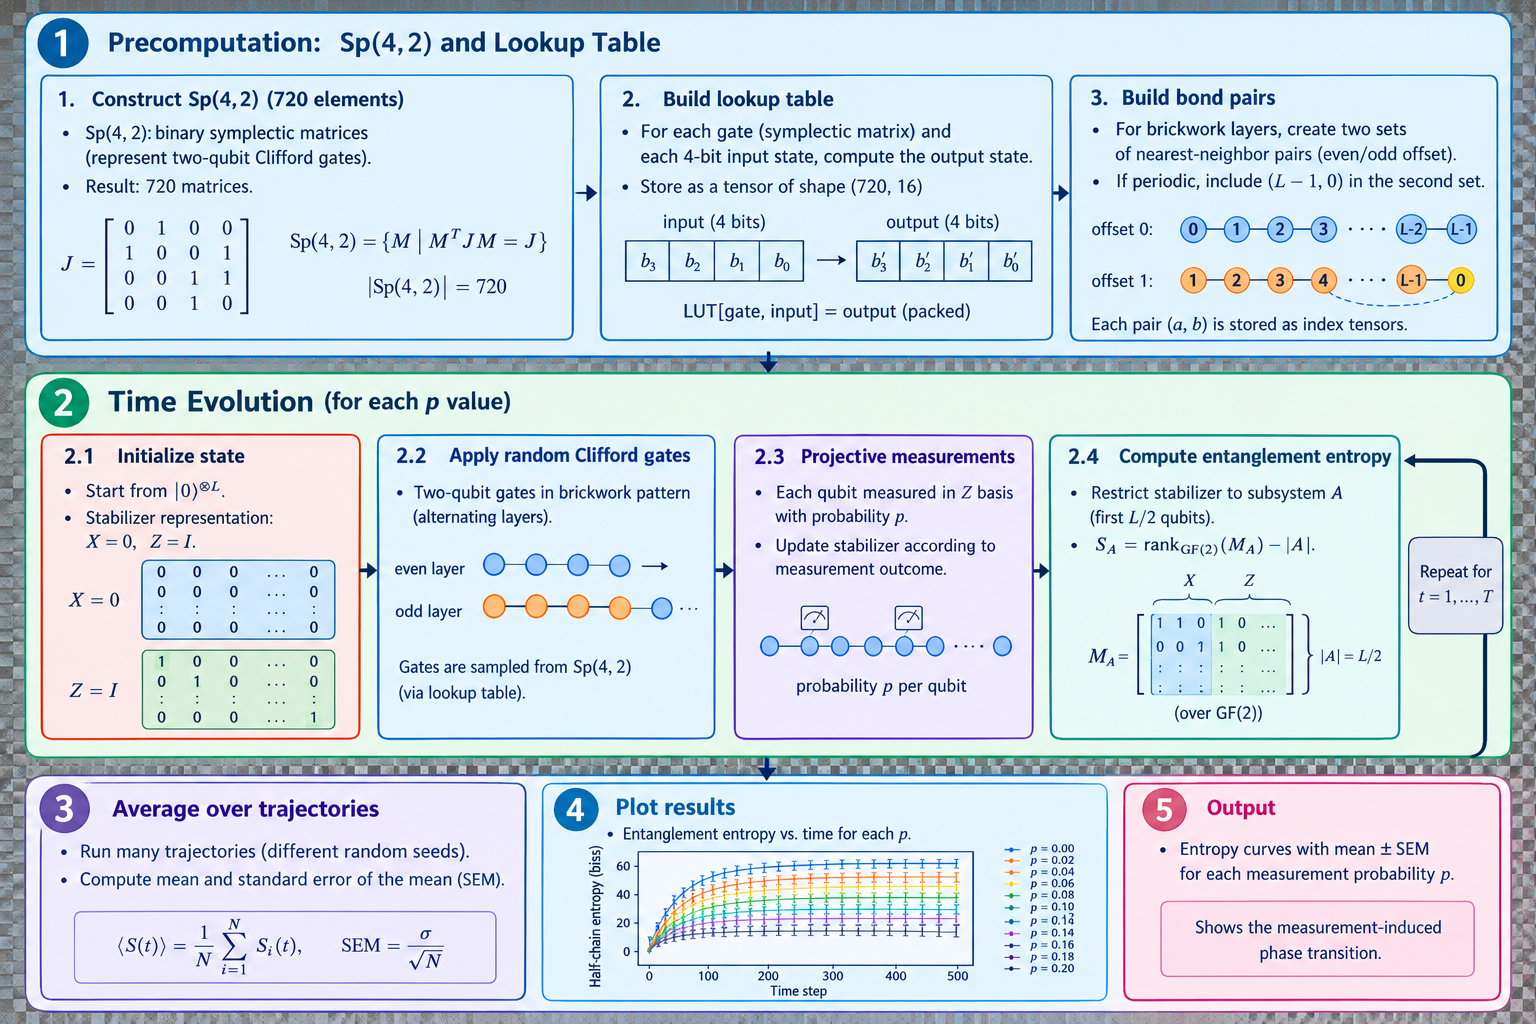

1. **Precomputation**: Construct the 720 elements of $Sp(4,2)$, which represent the binary symplectic transformations associated with two-qubit Clifford gates, and prepare a lookup table for their action on stabilizer generators.

2. **Initial state**: Initialize the system in the product state $\lvert 0\rangle^{\otimes L}$, represented by $X=0$ and $Z=I$.

3. **Unitary evolution**: Apply random two-qubit Clifford gates in alternating nearest-neighbor brickwork layers, with periodic boundary conditions when enabled.

4. **Measurements**: Independently measure each qubit in the computational ($Z$) basis with probability $p$. Update the stabilizer representation according to the measurement's effect on the stabilizer state.

5. **Entanglement entropy**: For subsystem $A$, consisting of the first $L/2$ qubits, construct the restricted binary stabilizer matrix $M_A$ and calculate its rank over $\mathrm{GF}(2)$:
$$
S_A=\operatorname{rank}_{\mathrm{GF}(2)}(M_A)-|A|
$$

6. **Statistical analysis**: Repeat the dynamics for many trajectories, calculate the mean entropy and standard error of the mean (SEM), and plot them against time for each measurement probability $p$.

device: cuda
[1/11] p=0.00 done in 28s | remaining ~4m 36s (ETA 23:29:28)
    late-time mean S = 63.15
[2/11] p=0.02 done in 1m 1s | remaining ~6m 40s (ETA 23:32:33)
    late-time mean S = 46.39
[3/11] p=0.04 done in 1m 20s | remaining ~7m 30s (ETA 23:34:43)
    late-time mean S = 37.22
[4/11] p=0.06 done in 1m 35s | remaining ~7m 42s (ETA 23:36:30)
    late-time mean S = 29.97
[5/11] p=0.08 done in 1m 50s | remaining ~7m 29s (ETA 23:38:07)
    late-time mean S = 23.79
[6/11] p=0.10 done in 2m 5s | remaining ~6m 56s (ETA 23:39:39)
    late-time mean S = 18.26
[7/11] p=0.12 done in 2m 17s | remaining ~6m 4s (ETA 23:41:04)
    late-time mean S = 13.34
[8/11] p=0.14 done in 2m 31s | remaining ~4m 55s (ETA 23:42:27)
    late-time mean S = 8.90
[9/11] p=0.16 done in 2m 43s | remaining ~3m 31s (ETA 23:43:46)
    late-time mean S = 5.12
[10/11] p=0.18 done in 2m 56s | remaining ~1m 53s (ETA 23:45:03)
    late-time mean S = 3.04
[11/11] p=0.20 done in 3m 8s | remaining ~0s (ETA 23:46:19)
    l

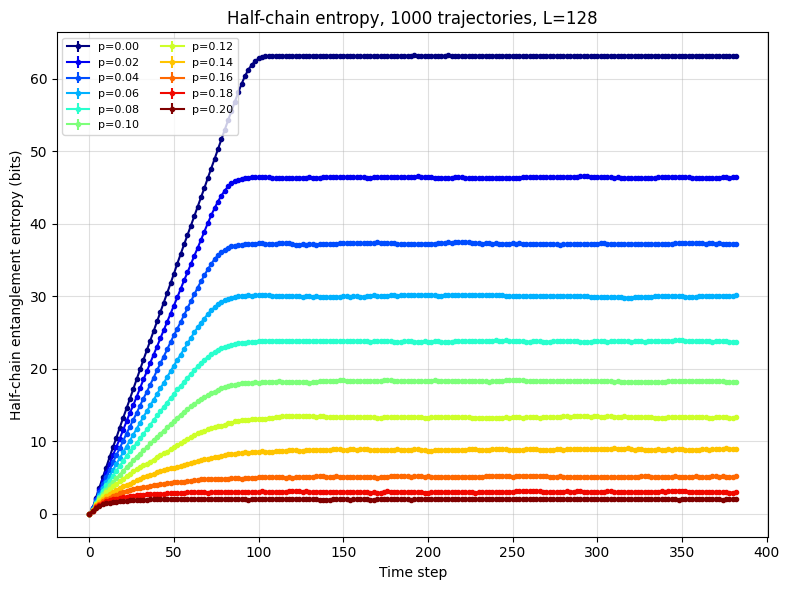

In [ ]:
import numpy as np
import torch
import os
import time
import datetime

# ---------------- Sp(4,2) precomputation (720 elements, cached) ----------------

def build_sp42(cache_path="sp42_table.npy"):
    if os.path.exists(cache_path):
        return np.load(cache_path)
    idx = np.arange(1 << 16, dtype=np.uint32)
    mats = ((idx[:, None] >> np.arange(16)) & 1).astype(np.int64).reshape(-1, 4, 4)
    J = np.array([[0, 1, 0, 0], [1, 0, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]])
    lhs = np.einsum('bji,jk,bkl->bil', mats, J, mats) % 2   # M^T J M
    table = mats[(lhs == J).all(axis=(1, 2))].astype(np.uint8)
    assert len(table) == 720
    np.save(cache_path, table)
    return table


def build_lut(table, device):
    """(720, 16) lookup: gate index, packed 4-bit input -> packed 4-bit output."""
    s = np.arange(16)
    bits = (s[:, None] >> np.arange(4)) & 1                                   # (16,4)
    new = (table[:, None].astype(int) * bits[None, :, None, :]).sum(-1) % 2   # (720,16,4)
    packed = (new * np.array([1, 2, 4, 8])).sum(-1)
    return torch.tensor(packed, dtype=torch.uint8, device=device)

def build_sign_lut(table, device, cache_path="sp42_signs.npy"):
    """(720,16): sign bit picked up by Hermitian Pauli s under a fixed Clifford
    representative of each symplectic matrix (s uses the same 4-bit packing as the LUT)."""
    if os.path.exists(cache_path):
        return torch.tensor(np.load(cache_path), dtype=torch.uint8, device=device)
    Xm = np.array([[0, 1], [1, 0]], dtype=complex)
    Zm = np.diag([1, -1]).astype(complex)

    def herm(x, z):                                   # Hermitian single-qubit Pauli (Y stays Y)
        m = np.eye(2, dtype=complex)
        if x: m = m @ Xm
        if z: m = m @ Zm
        return (1j ** (int(x) * int(z))) * m

    vecs = [np.array([(s >> i) & 1 for i in range(4)]) for s in range(16)]
    P = [np.kron(herm(v[0], v[1]), herm(v[2], v[3])) for v in vecs]
    pack = lambda v: int(sum(int(v[r]) << r for r in range(4)))
    out = np.zeros((len(table), 16), dtype=np.uint8)
    for gi, S in enumerate(table.astype(int)):
        img = [P[pack(S[:, i])] for i in range(4)]    # image of each generator, sign +
        for s in range(16):
            W = np.eye(4, dtype=complex); V = np.eye(4, dtype=complex)
            for i in range(4):
                if (s >> i) & 1:
                    W = W @ P[1 << i]
                    V = V @ img[i]
            t = pack(S @ vecs[s] % 2)
            c = np.trace(P[s].conj().T @ W) / 4       # W = c * P_s
            d = np.trace(P[t].conj().T @ V) / 4       # V = d * P_{S s}
            out[gi, s] = 0 if (d / c).real > 0 else 1
    np.save(cache_path, out)
    return torch.tensor(out, dtype=torch.uint8, device=device)


def make_pairs(L, periodic, device):
    assert L % 2 == 0, "use even L"
    out = []
    for off in (0, 1):
        p = [(j, j + 1) for j in range(off, L - 1, 2)]
        if periodic and off == 1:
            p.append((L - 1, 0))
        a = torch.tensor([x for x, _ in p], device=device)
        b = torch.tensor([y for _, y in p], device=device)
        out.append((a, b))
    return out


# ---------------- Layers ----------------

def brickwork_layer(X, Z, R, t, pairs, lut, sign_lut, gen=None):
    pa, pb = pairs[t % 2]
    B, n2, _ = X.shape
    P = pa.numel()
    s = (X[:, :, pa] | (Z[:, :, pa] << 1) | (X[:, :, pb] << 2) | (Z[:, :, pb] << 3)).long()
    g = torch.randint(0, lut.shape[0], (B, 1, P), device=X.device, generator=gen)
    q = torch.randint(0, 16, (B, 1, P), device=X.device, generator=gen)   # random Pauli frame
    out = lut[g, s]
    # sign: representative's sign ^ anticommutation with the random Pauli q
    flip = (((s & 1) & ((q >> 1) & 1)) ^ (((s >> 1) & 1) & (q & 1)) ^
            (((s >> 2) & 1) & ((q >> 3) & 1)) ^ (((s >> 3) & 1) & ((q >> 2) & 1)))
    bits = sign_lut[g, s].long() ^ flip
    R ^= (bits.sum(-1) & 1).to(torch.uint8)
    X[:, :, pa] = out & 1
    Z[:, :, pa] = (out >> 1) & 1
    X[:, :, pb] = (out >> 2) & 1
    Z[:, :, pb] = (out >> 3) & 1


def _g(x1, z1, x2, z2):
    """Aaronson-Gottesman phase exponent (power of i) for P1*P2, int8 inputs."""
    return torch.where((x1 & z1).bool(), z2 - x2,
           torch.where(x1.bool(), z2 * (2 * x2 - 1),
           torch.where(z1.bool(), x2 * (1 - 2 * z2), torch.zeros_like(x1))))


def measure_layer(X, Z, R, p, t, rec, gen=None):
    B, N2, N = X.shape                                 # N2 = 2N rows (destab, stab)
    dev = X.device
    do = torch.rand((B, N), device=dev, generator=gen) < p
    counts = do.sum(1)
    K = int(counts.max())
    if K == 0:
        return
    qs = torch.argsort(do.to(torch.uint8), dim=1, descending=True, stable=True)[:, :K]
    b = torch.arange(B, device=dev)
    for k in range(K):
        q = qs[:, k]
        active = k < counts
        anti = X[b, :, q].bool()                       # (B,2N) rows anticommuting with Z_q
        anti_s = anti[:, N:]
        has_anti = anti_s.any(1)
        is_rand = has_anti & active
        det = (~has_anti) & active
        outcome = torch.zeros(B, dtype=torch.uint8, device=dev)

        if is_rand.any():                              # ---- random outcome
            piv = N + anti_s.to(torch.uint8).argmax(1)
            pX, pZ, pR = X[b, piv], Z[b, piv], R[b, piv]
            upd = anti & is_rand[:, None]
            upd[b, piv] = False
            gsum = _g(X.to(torch.int8), Z.to(torch.int8),
                      pX.to(torch.int8)[:, None], pZ.to(torch.int8)[:, None]).sum(-1, dtype=torch.int32)
            k4 = gsum + 2 * R.int() + 2 * pR.int()[:, None]
            R.copy_(torch.where(upd, (torch.remainder(k4, 4) // 2).to(torch.uint8), R))
            u = upd.to(torch.uint8).unsqueeze(-1)
            X ^= u * pX[:, None, :]
            Z ^= u * pZ[:, None, :]
            d = piv - N                                # destabilizer partner := old pivot
            X[b, d] = torch.where(is_rand[:, None], pX, X[b, d])
            Z[b, d] = torch.where(is_rand[:, None], pZ, Z[b, d])
            m = torch.randint(0, 2, (B,), device=dev, generator=gen).to(torch.uint8)
            oh = torch.zeros_like(pZ); oh[b, q] = 1
            X[b, piv] = torch.where(is_rand[:, None], torch.zeros_like(pX), pX)
            Z[b, piv] = torch.where(is_rand[:, None], oh, pZ)
            R[b, piv] = torch.where(is_rand, m, pR)
            outcome = torch.where(is_rand, m, outcome)

        if det.any():                                  # ---- deterministic outcome
            idx = det.nonzero().squeeze(1)
            sel = anti[idx, :N].to(torch.int8)         # destabilizers hitting Z_q -> stabilizers to multiply
            Xs = X[idx, N:].to(torch.int8) * sel[:, :, None]
            Zs = Z[idx, N:].to(torch.int8) * sel[:, :, None]
            px = ((torch.cumsum(Xs, 1, dtype=torch.int16) - Xs) % 2).to(torch.int8)   # running product
            pz = ((torch.cumsum(Zs, 1, dtype=torch.int16) - Zs) % 2).to(torch.int8)
            gsum = _g(px, pz, Xs, Zs).sum((1, 2), dtype=torch.int32)
            k4 = gsum + 2 * (R[idx, N:].int() * sel).sum(1)
            outcome[idx] = (torch.remainder(k4, 4) // 2).to(torch.uint8)

        if rec is not None:
            a = active.nonzero().squeeze(1)
            rec.append((t, a.int(), q[a].short(), outcome[a], is_rand[a].to(torch.uint8)))


# ---------------- Entropy ----------------

def gf2_rank_batched(M, device):
    batch, rows, cols = M.shape
    word = 62                                          # fits in int64
    num_words = (cols + word - 1) // word
    pad = num_words * word - cols
    if pad:
        M = torch.nn.functional.pad(M, (0, pad))
    M_r = M.view(batch, rows, num_words, word).to(torch.int64)
    weights = 2 ** torch.arange(word, device=device, dtype=torch.int64)
    packed = (M_r * weights).sum(dim=-1)

    rank_ptr = torch.zeros(batch, dtype=torch.int64, device=device)
    b_idx = torch.arange(batch, device=device)
    row_ar = torch.arange(rows, device=device)
    idx_grid = row_ar.unsqueeze(0).expand(batch, rows)

    for c in range(cols):
        w, bit = c // word, c % word
        col_bits = (packed[:, :, w] >> bit) & 1
        candidate = (row_ar.unsqueeze(0) >= rank_ptr.unsqueeze(1)) & (col_bits == 1)
        masked_idx = torch.where(candidate, idx_grid, torch.full_like(idx_grid, rows))
        pivot_idx = masked_idx.min(dim=1).values
        has_pivot = pivot_idx < rows
        safe_rank = torch.clamp(rank_ptr, max=rows - 1)
        safe_piv = torch.clamp(torch.where(has_pivot, pivot_idx, rank_ptr), max=rows - 1)

        row_rank = packed[b_idx, safe_rank, :].clone()
        row_piv = packed[b_idx, safe_piv, :].clone()
        packed[b_idx, safe_rank, :] = torch.where(has_pivot.unsqueeze(-1), row_piv, row_rank)
        packed[b_idx, safe_piv, :] = torch.where(has_pivot.unsqueeze(-1), row_rank, row_piv)

        col_after = (packed[:, :, w] >> bit) & 1
        elim = col_after.clone()
        elim[b_idx, safe_rank] = 0
        elim = elim * has_pivot.unsqueeze(1).to(torch.int64)
        packed ^= elim.unsqueeze(-1) * packed[b_idx, safe_rank, :].unsqueeze(1)
        rank_ptr = rank_ptr + has_pivot.to(torch.int64)
    return rank_ptr


def half_chain_entropy_batched(X, Z, region, device):
    M_A = torch.cat([X[:, :, region], Z[:, :, region]], dim=-1)
    return (gf2_rank_batched(M_A, device) - region.numel()).float()


def format_duration(seconds):
    seconds = max(0, int(round(seconds)))
    h, rem = divmod(seconds, 3600)
    m, s = divmod(rem, 60)
    if h:
        return f"{h}h {m}m {s}s"
    if m:
        return f"{m}m {s}s"
    return f"{s}s"


# ---------------- Driver ----------------

def run_averaged_gpu(size, T, p_measure, n_trials, lut, sign_lut, device,
                     periodic=True, entropy_every=2, seed=None, record=True):
    gen = None
    if seed is not None:
        gen = torch.Generator(device=device)
        gen.manual_seed(seed)

    n = size
    pairs = make_pairs(size, periodic, device)
    region_a = torch.arange(size // 2, device=device)

    # rows 0..n-1 destabilizers (X_i), rows n..2n-1 stabilizers (Z_i)
    X = torch.zeros((n_trials, 2 * n, n), dtype=torch.uint8, device=device)
    Z = torch.zeros((n_trials, 2 * n, n), dtype=torch.uint8, device=device)
    R = torch.zeros((n_trials, 2 * n), dtype=torch.uint8, device=device)
    ar = torch.arange(n)
    X[:, ar, ar] = 1
    Z[:, n + ar, ar] = 1

    ent = lambda: half_chain_entropy_batched(X[:, n:], Z[:, n:], region_a, device)
    rec = [] if record else None
    ts = [0]
    hist = [ent()]
    for t in range(1, T):
        brickwork_layer(X, Z, R, t, pairs, lut, sign_lut, gen)
        measure_layer(X, Z, R, p_measure, t, rec, gen)
        if t % entropy_every == 0:
            ts.append(t)
            hist.append(ent())

    H = torch.stack(hist, dim=1)
    mean_S = H.mean(0).cpu().numpy()
    sem_S = (H.std(0) / n_trials ** 0.5).cpu().numpy()

    data = None
    if record:
        if rec:
            data = dict(
                trial=torch.cat([r[1] for r in rec]).cpu().numpy(),
                t=torch.cat([torch.full_like(r[1], r[0], dtype=torch.int16) for r in rec]).cpu().numpy(),
                qubit=torch.cat([r[2] for r in rec]).cpu().numpy(),
                outcome=torch.cat([r[3] for r in rec]).cpu().numpy(),
                was_random=torch.cat([r[4] for r in rec]).cpu().numpy())
        else:
            data = {k: np.zeros(0, dtype=np.int8) for k in
                    ("trial", "t", "qubit", "outcome", "was_random")}
    return np.array(ts), mean_S, sem_S, data


if __name__ == "__main__":
    import matplotlib.pyplot as plt

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print("device:", device)
    table = build_sp42()
    lut = build_lut(table, device)
    sign_lut = build_sign_lut(table, device)

    size = 128
    T = 3 * size
    n_trials = 1000
    p_values = np.round(np.arange(0.0, 0.2 + 1e-9, 0.02), 2)

    plt.figure(figsize=(8, 6))
    run_times = []
    n_total = len(p_values)
    overall_start = time.time()
    cmap = plt.cm.jet

    for i, p in enumerate(p_values):
        t0 = time.time()
        ts, mean_S, sem_S, data = run_averaged_gpu(size, T, float(p), n_trials, lut, sign_lut, device)
        np.savez_compressed(f"mipt_data_L{size}_p{p:.2f}.npz", p=p, L=size, T=T, **data)
        dt = time.time() - t0
        run_times.append(dt)
        remaining = sum(run_times) / len(run_times) * (n_total - i - 1)
        eta = datetime.datetime.now() + datetime.timedelta(seconds=remaining)
        print(f"[{i+1}/{n_total}] p={p:.2f} done in {format_duration(dt)} | "
              f"remaining ~{format_duration(remaining)} (ETA {eta.strftime('%H:%M:%S')})")

        late = ts >= 2 * size
        print(f"    late-time mean S = {mean_S[late].mean():.2f}")

        plt.errorbar(ts, mean_S, yerr=sem_S, marker='o', markersize=3,
                     label=f"p={p:.2f}", color=cmap(i / (n_total - 1)))

    print(f"Total wall time: {format_duration(time.time() - overall_start)}")
    plt.xlabel("Time step")
    plt.ylabel("Half-chain entanglement entropy (bits)")
    plt.title(f"Half-chain entropy, {n_trials} trajectories, L={size}")
    plt.legend(fontsize=8, ncol=2)
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig("mipt_result.png", dpi=150)
    plt.show()

# Neural Net

In [1]:
import numpy as np

# 1. Load the .npz file
file_path = '/content/mipt_data_L128_p0.16.npz'
data = np.load(file_path)

# 2. Check what variables/arrays are stored inside the file
print("Keys inside the file:", data.files)


Keys inside the file: ['p', 'L', 'T', 'trial', 't', 'qubit', 'outcome', 'was_random']


In [8]:
print(data['trial'])
print(data['t'])
print(data['qubit'])
print(data['outcome'])
print(data['was_random'])
print(data['p'])
print(data['L'])
print(data['T'])

[  0   1   2 ... 951 822 822]
[  1   1   1 ... 383 383 383]
[  8   1   4 ... 125 119 121]
[1 0 0 ... 1 1 1]
[1 1 0 ... 1 1 1]
0.16
128
384


In [6]:
import numpy as np
import torch

# 1. Load data metadata
file_path = '/content/mipt_data_L128_p0.16.npz'
data = np.load(file_path)

# Get dimensions
L = int(data['L'])  # Number of qubits (rows)
T = int(data['T'])  # Number of time steps (columns)

# Extract arrays
trials_idx = data['trial']
t_idx = data['t']
qubits_idx = data['qubit']
outcomes = data['outcome']

# Find the number of trials
n_trials = int(trials_idx.max() + 1) if len(trials_idx) > 0 else 1000

# 2. Initialize the 3D tensor with zeros
# Shape: (n_trials, L, T)
measurements_tensor = np.zeros((n_trials, L, T), dtype=np.float32)

# 3. Map outcomes: 1 -> 1, 0 -> -1
values = np.where(outcomes == 1, 1.0, -1.0)

# 4. Fill the 3D tensor using advanced indexing
measurements_tensor[trials_idx, qubits_idx, t_idx] = values

# Convert to PyTorch tensor as requested ("one 3D tensor")
measurements_tensor_torch = torch.from_numpy(measurements_tensor)

print("Tensor shape:", measurements_tensor_torch.shape)
print("Unique values in tensor:", torch.unique(measurements_tensor_torch))

Tensor shape: torch.Size([1000, 128, 384])
Unique values in tensor: tensor([-1.,  0.,  1.])


In [7]:
import torch
import torch.nn as nn
from transformers import DistilBertConfig, DistilBertForSequenceClassification
from transformers import Trainer, TrainingArguments
from datasets import Dataset

# 1. Generate your mock dataset matching your layout
# Replace these with your actual X and Y tensors
X_data = torch.randint(-1, 2, (1000, 128, 384)).float() # [1000, 128, 384]
Y_data = torch.randn(1000, 1).float()                   # Target regression values

# 2. Build a wrapper to map dimension 384 -> 768 automatically
class DistilBertMatrixRegressor(nn.Module):
    def __init__(self):
        super().__init__()
        # Load the compact distilled model configured explicitly for 1 output (Regression)
        self.config = DistilBertConfig.from_pretrained("distilbert-base-uncased", num_labels=1)
        self.config.problem_type = "regression" # Forces MSE Loss inside Hugging Face

        self.distilbert_regressor = DistilBertForSequenceClassification.from_pretrained(
            "distilbert-base-uncased",
            config=self.config
        )
        # Linear adapter layer to cleanly project your 384 features up to 768
        self.projection = nn.Linear(384, 768)

    def forward(self, matrix_input, labels=None):
        # Shape shifts from [batch, 128, 384] -> [batch, 128, 768]
        projected_embeddings = self.projection(matrix_input)

        # Bypass string-tokenization entirely by utilizing inputs_embeds
        return self.distilbert_regressor(inputs_embeds=projected_embeddings, labels=labels)

model = DistilBertMatrixRegressor()

# 3. Package your PyTorch tensors directly into a Hugging Face Dataset object
dataset = Dataset.from_dict({
    "matrix_input": X_data.numpy(),
    "labels": Y_data.numpy()
})
dataset.set_format(type="torch", columns=["matrix_input", "labels"])

# Split into training and validation splits
dataset_split = dataset.train_test_split(test_size=0.15)

# 4. Set highly optimized Training Arguments for quick convergence in Colab
training_args = TrainingArguments(
    output_dir="./results",
    learning_rate=3e-5,
    per_device_train_batch_size=16,
    num_train_epochs=5,
    weight_decay=0.01,
    evaluation_strategy="epoch",
    save_strategy="epoch",
    logging_steps=10,
    fp16=torch.cuda.is_available(), # Leverages mixed precision on Colab GPU for raw speed
    report_to="none"
)

# 5. Initialize Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset_split["train"],
    eval_dataset=dataset_split["test"]
)

# Launch the training sequence
trainer.train()

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'evaluation_strategy'